<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/7_6_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile frekans_filtresi.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>
#include <random>

const double PI = std::acos(-1.0);

// --- YARDIMCI FONKSİYONLAR ---
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();
    for (size_t i = 0; i < n; ++i) {
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

void addNoise(std::vector<double>& vec, double noise_ratio) {
    double max_amp = 0.0;
    for (double v : vec) if (std::abs(v) > max_amp) max_amp = std::abs(v);
    double bound = max_amp * noise_ratio;

    std::random_device rd;
    std::mt19937 gen(rd());
    std::uniform_real_distribution<> dis(-bound, bound);
    for (double& v : vec) v += dis(gen);
}

// Karmaşık (Complex) sayıları tutmak için yapı
struct ComplexSpectrum {
    std::vector<double> real;
    std::vector<double> imag;
};

// 1. DFT Hesaplama (Frekans Uzayına Geçiş)
ComplexSpectrum computeDFT(const std::vector<double>& input_signal) {
    size_t N = input_signal.size();
    ComplexSpectrum out;
    out.real.resize(N, 0.0);
    out.imag.resize(N, 0.0);

    for (size_t k = 0; k < N; ++k) {
        double r_sum = 0.0;
        double i_sum = 0.0;
        for (size_t x = 0; x < N; ++x) {
            double angle = 2.0 * PI * k * x / N;
            r_sum += input_signal[x] * std::cos(angle);
            i_sum -= input_signal[x] * std::sin(angle);
        }
        out.real[k] = r_sum;
        out.imag[k] = i_sum;
    }
    return out;
}

// 2. FREKANS FİLTRESİ: Eşik değerinin altındaki harmonikleri sıfırla
ComplexSpectrum applyFrequencyFilter(const ComplexSpectrum& spectrum, double threshold, size_t N) {
    ComplexSpectrum filtered = spectrum;
    for (size_t k = 0; k < N; ++k) {
        // Genliği (Magnitude) hesapla ve N'ye normalize et
        double magnitude = std::sqrt(spectrum.real[k] * spectrum.real[k] + spectrum.imag[k] * spectrum.imag[k]) / N;

        // Genlik eşik değerinin altındaysa frekansı (reel ve sanal kısmını) tamamen sıfırla
        if (magnitude < threshold) {
            filtered.real[k] = 0.0;
            filtered.imag[k] = 0.0;
        }
    }
    return filtered;
}

// 3. TERS DFT (IDFT) Hesaplama (Zaman/Uzam Uzayına Geri Dönüş)
std::vector<double> computeIDFT(const ComplexSpectrum& spectrum) {
    size_t N = spectrum.real.size();
    std::vector<double> output_signal(N, 0.0);

    for (size_t x = 0; x < N; ++x) {
        double r_sum = 0.0;
        for (size_t k = 0; k < N; ++k) {
            double angle = 2.0 * PI * k * x / N;
            // IDFT Formülü: Real*cos - Imag*sin
            r_sum += spectrum.real[k] * std::cos(angle) - spectrum.imag[k] * std::sin(angle);
        }
        // IDFT'de toplam değere 1/N çarpanı uygulanır
        output_signal[x] = r_sum / N;
    }
    return output_signal;
}

int main() {
    size_t N = 512;

    // Sinyal 1: Frekans 50, Genlik 12
    std::vector<double> sig1(N);
    generateSineWave(sig1, 12.0, 50.0, 0.0);
    addNoise(sig1, 0.40);

    // Sinyal 2: Frekans 30, Genlik 5
    std::vector<double> sig2(N);
    generateSineWave(sig2, 5.0, 30.0, 0.0);
    addNoise(sig2, 0.40);

    // Toplam Sinyal
    std::vector<double> sig_sum(N);
    for (size_t i = 0; i < N; ++i) sig_sum[i] = sig1[i] + sig2[i];

    // --- FREKANS UZAYINDA FİLTRELEME İŞLEMLERİ ---
    double threshold = 2.5; // Gürültüleri ezecek, 5 ve 12 genlikli ana sinyalleri koruyacak eşik

    // 1. DFT
    ComplexSpectrum spec1 = computeDFT(sig1);
    ComplexSpectrum spec2 = computeDFT(sig2);
    ComplexSpectrum spec_sum = computeDFT(sig_sum);

    // 2. Filtreleme
    ComplexSpectrum filtered_spec1 = applyFrequencyFilter(spec1, threshold, N);
    ComplexSpectrum filtered_spec2 = applyFrequencyFilter(spec2, threshold, N);
    ComplexSpectrum filtered_spec_sum = applyFrequencyFilter(spec_sum, threshold, N);

    // 3. IDFT (Sinyali Geri Çizme)
    std::vector<double> filtered_sig1 = computeIDFT(filtered_spec1);
    std::vector<double> filtered_sig2 = computeIDFT(filtered_spec2);
    std::vector<double> filtered_sig_sum = computeIDFT(filtered_spec_sum);

    // Çıktıları kaydetme
    std::ofstream outFile("filtreli_sinyaller.csv");
    outFile << "Index,Sig1_Noisy,Sig1_Filtered,Sig2_Noisy,Sig2_Filtered,SigSum_Noisy,SigSum_Filtered\n";
    for (size_t i = 0; i < N; ++i) {
        outFile << i << ","
                << sig1[i] << "," << filtered_sig1[i] << ","
                << sig2[i] << "," << filtered_sig2[i] << ","
                << sig_sum[i] << "," << filtered_sig_sum[i] << "\n";
    }
    outFile.close();

    std::cout << "Sinyaller filtrelendi, IDFT ile geri donusturuldu ve diske kaydedildi." << std::endl;
    return 0;
}

Writing frekans_filtresi.cpp


In [2]:
!g++ frekans_filtresi.cpp -o frekans_filtresi
!./frekans_filtresi

Sinyaller filtrelendi, IDFT ile geri donusturuldu ve diske kaydedildi.


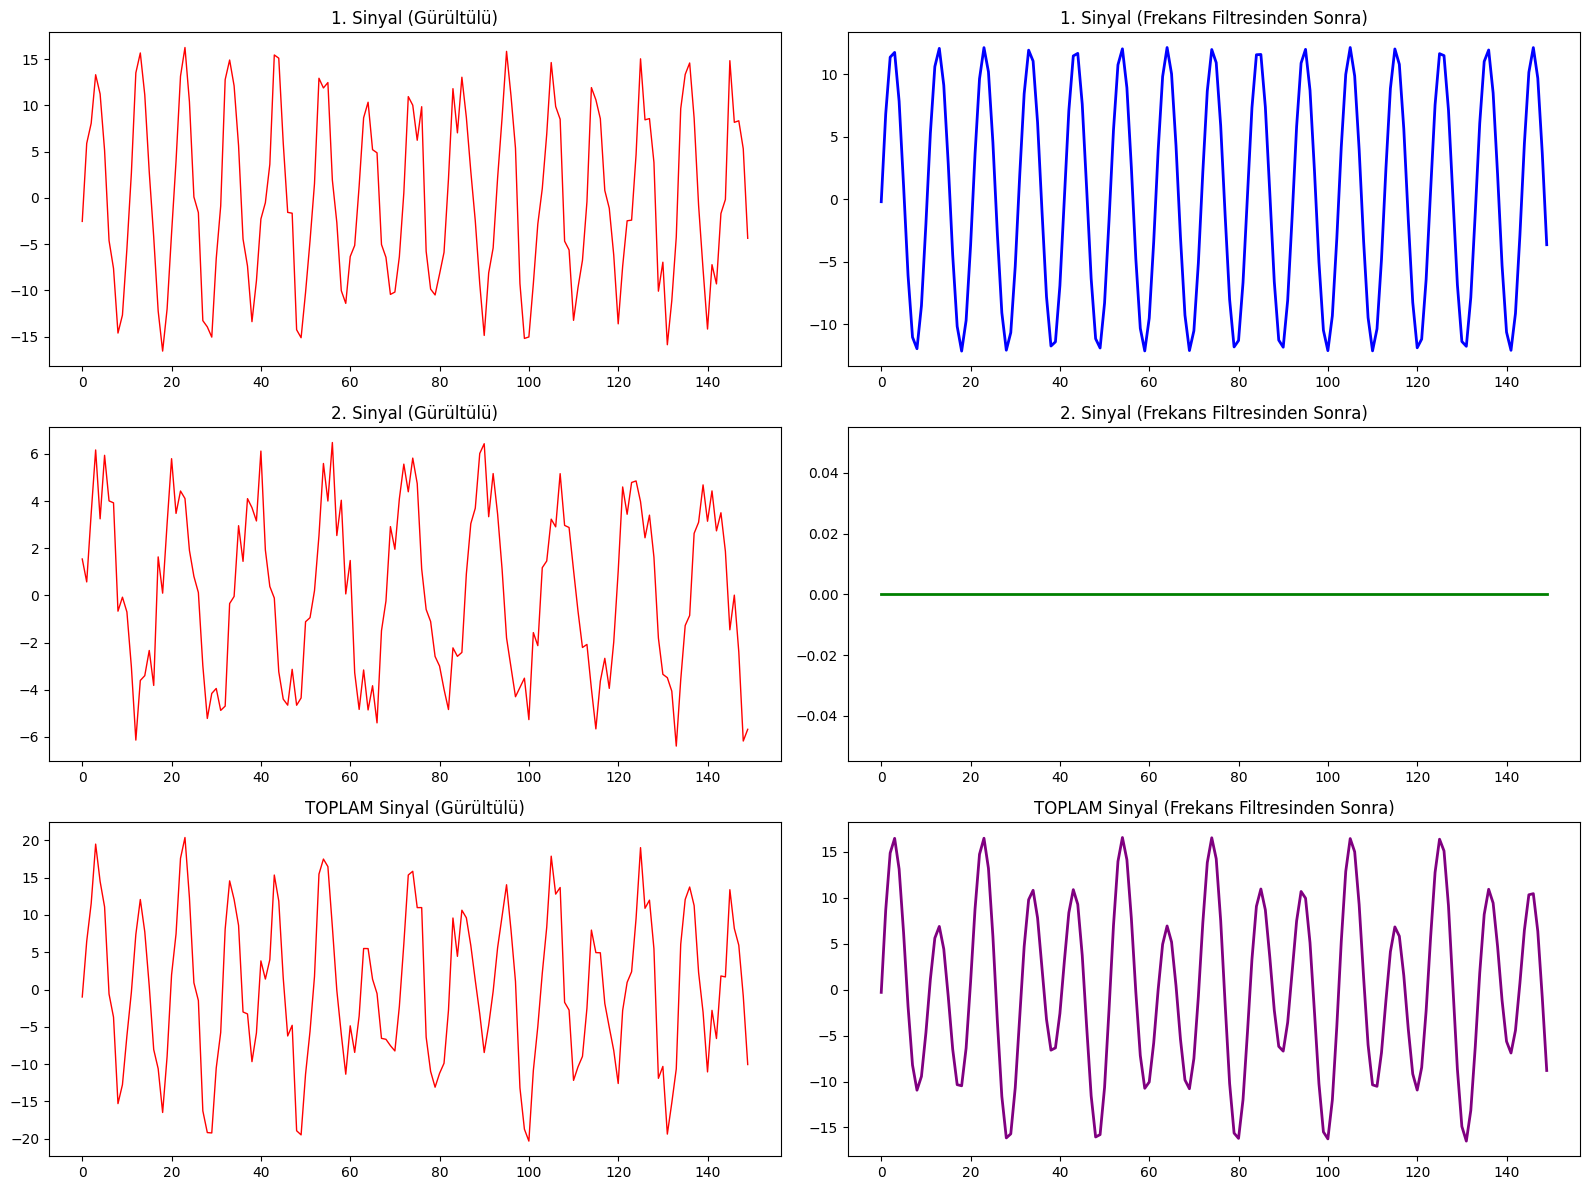

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('filtreli_sinyaller.csv')
limit = 150 # Dalgaları net görmek için x eksenini kısıtlıyoruz

plt.figure(figsize=(16, 12))

# 1. Sinyal Kıyaslaması
plt.subplot(3, 2, 1)
plt.plot(df['Index'][:limit], df['Sig1_Noisy'][:limit], color='red', linewidth=1)
plt.title('1. Sinyal (Gürültülü)')
plt.subplot(3, 2, 2)
plt.plot(df['Index'][:limit], df['Sig1_Filtered'][:limit], color='blue', linewidth=2)
plt.title('1. Sinyal (Frekans Filtresinden Sonra)')

# 2. Sinyal Kıyaslaması
plt.subplot(3, 2, 3)
plt.plot(df['Index'][:limit], df['Sig2_Noisy'][:limit], color='red', linewidth=1)
plt.title('2. Sinyal (Gürültülü)')
plt.subplot(3, 2, 4)
plt.plot(df['Index'][:limit], df['Sig2_Filtered'][:limit], color='green', linewidth=2)
plt.title('2. Sinyal (Frekans Filtresinden Sonra)')

# Toplam Sinyal Kıyaslaması
plt.subplot(3, 2, 5)
plt.plot(df['Index'][:limit], df['SigSum_Noisy'][:limit], color='red', linewidth=1)
plt.title('TOPLAM Sinyal (Gürültülü)')
plt.subplot(3, 2, 6)
plt.plot(df['Index'][:limit], df['SigSum_Filtered'][:limit], color='purple', linewidth=2)
plt.title('TOPLAM Sinyal (Frekans Filtresinden Sonra)')

plt.tight_layout()
plt.show()